In [1]:
# ==============================================================================
# 📦 CELL 1: CÀI ĐẶT THƯ VIỆN BẮT BUỘC (CHẠY ĐẦU TIÊN TRÊN COLAB / KAGGLE)
# ==============================================================================
try:
    get_ipython().system('pip install -q timm torchvision scikit-learn seaborn pandas opencv-python matplotlib tqdm')
    print("✅ Cài đặt thư viện thành công qua pip!")
except Exception:
    import sys, subprocess
    pkgs = ["timm", "torchvision", "scikit-learn", "seaborn", "pandas", "opencv-python", "matplotlib", "tqdm"]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)
    print("✅ Cài đặt thư viện thành công qua subprocess!")


✅ Cài đặt thư viện thành công qua pip!


# 🚀 01. Huấn luyện Tối ưu Unimodal Vision: ConvNeXt V2-Base (Teacher Backbone)

**Dự án:** Nhận diện độ chín sầu riêng bằng Chưng cất tri thức Đa phương thức (Durian Ripeness CMKD)  
**Phụ trách:** Member 1 (Vision Lead)  
**Mục tiêu F1-Score:** Đạt $\ge \mathbf{0.85 - 0.90}$ trên cả cấp độ Ảnh (*Image-level*) và cấp độ Quả (*Fruit-level Voting*).

---

### 🌟 5 Đột phá Kỹ thuật giải quyết triệt để vấn đề kẹt F1 (~0.58):
1. **Nâng độ phân giải lên $384 	imes 384$ (`IMAGE_SIZE = 384`):** Giúp mô hình nhìn rõ các vi rãnh giãn nở và chân gai thay vì bị bệt mờ ở mức 224.
2. **Phân tầng Tốc độ học (Differential Learning Rate) + Warmup:**
   - **Backbone (`convnextv2_base`):** Tốc độ học nhỏ ($1	imes 10^{-5}$) để bảo tồn đặc trưng cực đẹp của FCMAE ImageNet-1K.
   - **Classifier Head:** Tốc độ học lớn ($5	imes 10^{-4}$) để thích ứng nhanh với 3 lớp sầu riêng.
   - **5 Epochs Warmup:** Tránh hiện tượng *Gradient Shock* phá hỏng mô hình ở những bước đầu.
3. **Trì hoãn Mixup / CutMix (Delayed Augmentation):**
   - 10 Epochs đầu: Tắt hoàn toàn Mixup (`prob = 0.0`) để mô hình học chắc mẫu nguyên bản.
   - Từ Epoch 11: Bật Mixup nhẹ nhàng (`prob = 0.3`, $lpha = 0.2$) để tăng tính tổng quát hóa.
4. **Trọng số Lớp (Class-Weighted Loss):** Phạt nặng khi đoán sai lớp thiểu số `Unripe` (vốn chỉ có 335 ảnh so với 600 ảnh `Overripe`).
5. **Fresh Training khởi tạo lại sạch 100% (`FORCE_FRESH_START = True`):** Bỏ qua checkpoint cũ bị kẹt, nạp trọng số sạch từ ImageNet để hội tụ chuẩn xác.


In [2]:
# 2. Import các thư viện và thiết lập môi trường tính toán
import gc
import json
import math
import os
import random
import sys
import time
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

# Cố định Seed ngẫu nhiên để đảm bảo tính tái lập (Reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Thiết lập thiết bị tính toán (GPU / MPS / CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"✅ Thiết bị tính toán đang dùng: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   • Tên GPU : {torch.cuda.get_device_name(0)}")
    print(f"   • VRAM    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


✅ Thiết bị tính toán đang dùng: cuda
   • Tên GPU : NVIDIA L4
   • VRAM    : 22.03 GB


In [3]:
# 3. Kết nối Google Drive và Thiết lập đường dẫn Dữ liệu & Checkpoints
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

def find_project_root() -> str:
    cur = os.path.abspath(".")
    for _ in range(5):
        if os.path.isdir(os.path.join(cur, "data")) and os.path.isdir(os.path.join(cur, "checkpoints")):
            return cur
        parent = os.path.dirname(cur)
        if parent == cur:
            break
        cur = parent
    return os.path.abspath("../../..")

if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Đã kết nối thành công Google Drive tại /content/drive")
    
    DATA_SPLIT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"
    DATA_FINAL_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/final"
    CHECKPOINT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal"
    DEMO_CACHE_DIR = "/content/colab_temp_cache/demo_vision_unimodal"
else:
    PROJECT_ROOT = find_project_root()
    DATA_SPLIT_DIR = os.path.join(PROJECT_ROOT, "data", "split_data")
    DATA_FINAL_DIR = os.path.join(PROJECT_ROOT, "data", "final")
    CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "checkpoints", "unimodal")
    DEMO_CACHE_DIR = os.path.join(PROJECT_ROOT, ".demo_vision_cache")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "best_vision_unimodal.pth")
LAST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "last_vision_unimodal.pth")
BACKBONE_TEACHER_PATH = os.path.join(CHECKPOINT_DIR, "vision_backbone_teacher.pth")

print(f"\n[CẤU HÌNH ĐƯỜNG DẪN]")
print(f"  • Thư mục Final Data       : {DATA_FINAL_DIR}")
print(f"  • Thư mục Checkpoint       : {CHECKPOINT_DIR}")
print(f"  • Target Best Checkpoint   : {BEST_CHECKPOINT_PATH}")


Mounted at /content/drive
✅ Đã kết nối thành công Google Drive tại /content/drive

[CẤU HÌNH ĐƯỜNG DẪN]
  • Thư mục Final Data       : /content/drive/MyDrive/durian-ripeness-cmkd/data/final
  • Thư mục Checkpoint       : /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal
  • Target Best Checkpoint   : /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/best_vision_unimodal.pth


In [4]:
# 4. Quét dữ liệu và Tính toán Trọng số Lớp (Class Weights) để giải quyết Class Imbalance
RIPENESS_ORDER = ["Unripe", "Ripe", "Overripe"]
LABEL_TO_IDX = {name: idx for idx, name in enumerate(RIPENESS_ORDER)}
IDX_TO_LABEL = {idx: name for name, idx in LABEL_TO_IDX.items()}

def parse_label_from_filename(filename: str) -> Optional[str]:
    fn = filename.lower()
    if "_unripe" in fn or "-un" in fn or "_immature" in fn:
        return "Unripe"
    elif "_overripe" in fn or "-or" in fn or "_senescent" in fn:
        return "Overripe"
    elif "_ripe" in fn or "-ri" in fn or "_mature" in fn:
        return "Ripe"
    return None

def collect_split_images(data_split_dir: str, data_final_dir: str) -> Dict[str, List[Dict]]:
    splits_data = {"train": [], "val": [], "test": []}
    used_source = None
    
    # 1. Quét từ data/final/
    if os.path.isdir(data_final_dir):
        for sp in ["train", "val", "test"]:
            actual_sp_dir = os.path.join(data_final_dir, "valid" if (sp == "val" and not os.path.isdir(os.path.join(data_final_dir, "val"))) else sp, "rgb")
            if os.path.isdir(actual_sp_dir):
                files = [f for f in os.listdir(actual_sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(actual_sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/final"

    # 2. Quét từ data/split_data/
    if sum(len(v) for v in splits_data.values()) == 0 and os.path.isdir(data_split_dir):
        for sp in ["train", "val", "test"]:
            sp_dir = os.path.join(data_split_dir, sp, "dataset_clean_rgb")
            if os.path.isdir(sp_dir):
                files = [f for f in os.listdir(sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/split_data"

    print(f"[*] Nguồn dữ liệu đã phát hiện: {used_source or 'Chưa tìm thấy ảnh thật'}")
    return splits_data

image_splits = collect_split_images(DATA_SPLIT_DIR, DATA_FINAL_DIR)
total_images = sum(len(v) for v in image_splits.values())

# Fallback demo cache nếu môi trường trống
if total_images == 0:
    print(f"⚠️ Đang tạo bộ ảnh demo giả lập tại {DEMO_CACHE_DIR}...")
    os.makedirs(DEMO_CACHE_DIR, exist_ok=True)
    for sp, count in [("train", 12), ("val", 6), ("test", 6)]:
        sp_dir = os.path.join(DEMO_CACHE_DIR, sp)
        os.makedirs(sp_dir, exist_ok=True)
        for i in range(count):
            lbl = RIPENESS_ORDER[i % 3]
            fname = f"durian_{i+1:03d}_A_{lbl}_TOP.jpg"
            fpath = os.path.join(sp_dir, fname)
            if not os.path.exists(fpath):
                arr = np.random.randint(40, 180, (384, 384, 3), dtype=np.uint8)
                cv2.circle(arr, (192, 192), 120, (50, 120, 40) if lbl=="Unripe" else ((30, 140, 180) if lbl=="Ripe" else (20, 80, 160)), -1)
                cv2.imwrite(fpath, arr)
            image_splits[sp].append({
                "filepath": fpath,
                "filename": fname,
                "label": lbl,
                "label_idx": LABEL_TO_IDX[lbl],
                "split": sp
            })

# Thống kê phân phối ảnh
summary_records = []
for sp in ["train", "val", "test"]:
    df_sp = pd.DataFrame(image_splits[sp])
    if len(df_sp) > 0:
        counts = df_sp["label"].value_counts().to_dict()
        summary_records.append({
            "Split": sp,
            "Unripe": counts.get("Unripe", 0),
            "Ripe": counts.get("Ripe", 0),
            "Overripe": counts.get("Overripe", 0),
            "Tổng số ảnh": len(df_sp)
        })
df_summary = pd.DataFrame(summary_records)
print(f"\n📊 [PHÂN PHỐI ẢNH THỰC TẾ TRÊN CÁC TẬP]")
print(df_summary.to_string(index=False))

# --- TÍNH TOÁN CLASS WEIGHTS DỰA TRÊN TẬP TRAIN ---
df_train = pd.DataFrame(image_splits["train"])
train_counts = [df_train["label"].value_counts().get(c, 1) for c in RIPENESS_ORDER]
total_train = sum(train_counts)

# Công thức trọng số nghịch đảo: w_c = N / (K * N_c)
class_weights_val = [total_train / (len(RIPENESS_ORDER) * count) for count in train_counts]
CLASS_WEIGHTS = torch.tensor(class_weights_val, dtype=torch.float).to(DEVICE)

print(f"\n⚖️ [TRỌNG SỐ LỚP - CLASS WEIGHTS ĐỂ CHỐNG LỆCH PHA]")
for name, count, w in zip(RIPENESS_ORDER, train_counts, class_weights_val):
    print(f"  • {name:<9}: {count:>4} ảnh  -->  Trọng số: {w:.3f}")


[*] Nguồn dữ liệu đã phát hiện: data/final

📊 [PHÂN PHỐI ẢNH THỰC TẾ TRÊN CÁC TẬP]
Split  Unripe  Ripe  Overripe  Tổng số ảnh
train     335   562       600         1497
  val      60   102       120          282
 test      60   114       124          298

⚖️ [TRỌNG SỐ LỚP - CLASS WEIGHTS ĐỂ CHỐNG LỆCH PHA]
  • Unripe   :  335 ảnh  -->  Trọng số: 1.490
  • Ripe     :  562 ảnh  -->  Trọng số: 0.888
  • Overripe :  600 ảnh  -->  Trọng số: 0.832


In [5]:
# 5. Tiền xử lý độ phân giải cao 384x384, CLAHE kênh L và Cơ chế Trì hoãn Mixup
class CLAHETransform:
    """Áp dụng CLAHE chuẩn trên kênh L (LAB) để tôn vinh kết cấu vi mô rãnh gai."""
    def __init__(self, clip_limit: float = 2.0, tile_grid_size: Tuple[int, int] = (8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img: Image.Image) -> Image.Image:
        np_img = np.array(img)
        lab = cv2.cvtColor(np_img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = self.clahe.apply(l)
        enhanced_lab = cv2.merge((l_clahe, a, b))
        enhanced_rgb = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced_rgb)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# NÂNG CẤP ĐỘ PHÂN GIẢI LÊN 384x384 ĐỂ BẮT RÕ RÃNH GAI VI MÔ
IMAGE_SIZE = 384

def get_train_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.RandomResizedCrop(image_size, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def get_eval_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.Resize(int(image_size * 1.08)),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def apply_mixup(images: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Mixup nhẹ nhàng (alpha=0.2) để tránh làm nhiễu dữ liệu lúc đầu."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    batch_size = images.size(0)
    index = torch.randperm(batch_size).to(images.device)
    mixed_images = lam * images + (1 - lam) * images[index]
    return mixed_images, labels, labels[index], lam


In [6]:
# 6. PyTorch Dataset và Khởi tạo DataLoaders tối ưu cho GPU L4 (24GB VRAM)
class DurianRipenessDataset(Dataset):
    def __init__(self, records: List[Dict], transform: Optional[transforms.Compose] = None):
        self.records = records
        self.transform = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int, str]:
        item = self.records[idx]
        with Image.open(item["filepath"]) as img:
            rgb_img = img.convert("RGB")
        
        tensor_img = self.transform(rgb_img) if self.transform else transforms.ToTensor()(rgb_img)
        return tensor_img, item["label_idx"], item["filename"]

# Với ảnh 384x384, BATCH_SIZE = 16 là điểm vàng tuyệt đối (ổn định gradient và vừa vặn VRAM)
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
NUM_WORKERS = 4 if torch.cuda.is_available() else 0

train_dataset = DurianRipenessDataset(image_splits["train"], transform=get_train_transforms(IMAGE_SIZE))
val_dataset = DurianRipenessDataset(image_splits["val"], transform=get_eval_transforms(IMAGE_SIZE))
test_dataset = DurianRipenessDataset(image_splits["test"], transform=get_eval_transforms(IMAGE_SIZE))

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=(len(train_dataset) > BATCH_SIZE)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print(f"✅ DataLoaders đã sẵn sàng với độ phân giải {IMAGE_SIZE}x{IMAGE_SIZE}:")
print(f"  • Train: {len(train_dataset)} ảnh ({len(train_loader)} batches)")
print(f"  • Val  : {len(val_dataset)} ảnh ({len(val_loader)} batches)")
print(f"  • Test : {len(test_dataset)} ảnh ({len(test_loader)} batches)")


✅ DataLoaders đã sẵn sàng với độ phân giải 384x384:
  • Train: 1497 ảnh (93 batches)
  • Val  : 282 ảnh (18 batches)
  • Test : 298 ảnh (19 batches)


In [7]:
# 7. Khởi tạo Mô hình ConvNeXt V2-Base (Trọng số gốc FCMAE ImageNet-1K)
class ConvNeXtV2BaseTeacherVision(nn.Module):
    def __init__(self, num_classes: int = 3, drop_path_rate: float = 0.2, head_dropout: float = 0.3):
        super().__init__()
        print(f"[*] Đang nạp pre-trained weights sạch: 'convnextv2_base.fcmae_ft_in1k'...")
        self.backbone = timm.create_model(
            'convnextv2_base.fcmae_ft_in1k',
            pretrained=True,
            num_classes=0,
            drop_path_rate=drop_path_rate
        )
        self.num_features = self.backbone.num_features # 1024
        
        # Classifier Head chuyên dụng
        self.head = nn.Sequential(
            nn.Dropout(p=head_dropout),
            nn.Linear(self.num_features, num_classes)
        )

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        features = self.forward_features(x)
        logits = self.head(features)
        return logits, features

model = ConvNeXtV2BaseTeacherVision(
    num_classes=len(RIPENESS_ORDER),
    drop_path_rate=0.2,
    head_dropout=0.3
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"✅ Khởi tạo thành công ConvNeXt V2-Base: {total_params / 1e6:.2f} M params (Feature Dim: {model.num_features})")


[*] Đang nạp pre-trained weights sạch: 'convnextv2_base.fcmae_ft_in1k'...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  355MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ Khởi tạo thành công ConvNeXt V2-Base: 87.70 M params (Feature Dim: 1024)


In [8]:
# 8. Cấu hình Differential Learning Rate, Warmup Scheduler và Class-Weighted Loss
# --- PHÂN TẦNG TỐC ĐỘ HỌC ĐỂ BẢO VỆ BACKBONE ---
BACKBONE_LR = 1e-5   # Tốc độ học rất nhỏ cho Backbone để giữ đặc trưng xịn
HEAD_LR = 5e-4       # Tốc độ học lớn cho Head để thích ứng nhanh phân loại 3 lớp
WEIGHT_DECAY = 1e-2  # Giảm nhẹ weight decay tránh làm triệt tiêu gradient

decay_backbone, no_decay_backbone = [], []
decay_head, no_decay_head = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    is_no_decay = (param.ndim <= 1 or name.endswith(".bias") or "norm" in name.lower() or "grn" in name.lower())
    if "head" in name:
        if is_no_decay:
            no_decay_head.append(param)
        else:
            decay_head.append(param)
    else:
        if is_no_decay:
            no_decay_backbone.append(param)
        else:
            decay_backbone.append(param)

optimizer_grouped_parameters = [
    {"params": decay_backbone, "weight_decay": WEIGHT_DECAY, "lr": BACKBONE_LR},
    {"params": no_decay_backbone, "weight_decay": 0.0, "lr": BACKBONE_LR},
    {"params": decay_head, "weight_decay": WEIGHT_DECAY, "lr": HEAD_LR},
    {"params": no_decay_head, "weight_decay": 0.0, "lr": HEAD_LR},
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, eps=1e-8)

EPOCHS = 40  # Đã nâng lên 40 để sau khi resume từ epoch 22 vẫn học tiếp đủ 18 epochs nữa
WARMUP_EPOCHS = 5

# Scheduler kết hợp: 5 Epochs Linear Warmup + Cosine Annealing
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=(EPOCHS - WARMUP_EPOCHS), eta_min=1e-6)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

# Loss function tích hợp Class Weights và Label Smoothing nhẹ 0.05
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=0.05)

print("✅ Đã thiết lập xong Bộ tối ưu hóa:")
print(f"  • Backbone LR : {BACKBONE_LR} (Bảo tồn pretrain)")
print(f"  • Head LR     : {HEAD_LR} (Học nhanh)")
print(f"  • Warmup      : {WARMUP_EPOCHS} epochs đầu")
print(f"  • Loss        : CrossEntropyLoss (Có Class Weights + Label Smoothing 0.05)")


✅ Đã thiết lập xong Bộ tối ưu hóa:
  • Backbone LR : 1e-05 (Bảo tồn pretrain)
  • Head LR     : 0.0005 (Học nhanh)
  • Warmup      : 5 epochs đầu
  • Loss        : CrossEntropyLoss (Có Class Weights + Label Smoothing 0.05)


In [9]:
# 9. Cơ chế Quản lý Checkpoints, Fresh Training & Early Stopping chống Overfit
FORCE_FRESH_START = True  # BẬT TRUE ĐỂ BẮT ĐẦU HUẤN LUYỆN LẠI SẠCH 100% TỪ PRETRAIN

class EarlyStopping:
    """Tự động ngắt huấn luyện khi Val Loss không giảm liên tiếp 'patience' epochs để chống Overfit."""
    def __init__(self, patience: int = 7, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False

    def __call__(self, current_val_loss: float) -> bool:
        # Nếu Val Loss giảm sâu hơn (cải thiện) ít nhất min_delta
        if current_val_loss < (self.best_loss - self.min_delta):
            self.best_loss = current_val_loss
            self.counter = 0
            return True  # Cải thiện -> Lưu checkpoint
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
            return False

def save_training_checkpoint(state_dict_model, state_dict_optimizer, state_dict_scheduler, epoch, best_val_loss, best_val_f1, history, save_path):
    payload = {
        "epoch": epoch,
        "model_state_dict": state_dict_model,
        "optimizer_state_dict": state_dict_optimizer,
        "scheduler_state_dict": state_dict_scheduler,
        "best_val_loss": best_val_loss,
        "best_val_f1": best_val_f1,
        "history": history,
        "model_architecture": "convnextv2_base",
        "feature_dim": 1024,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }
    torch.save(payload, save_path)

# Khởi tạo Early Stopping giám sát Val Loss với patience = 7 epochs
early_stopping = EarlyStopping(patience=7, min_delta=1e-4)

if FORCE_FRESH_START:
    print("🚀 [CHẾ ĐỘ FRESH START ĐÃ KÍCH HOẠT] Khởi tạo huấn luyện sạch 100% từ ImageNet Pretrain.")
    print("   • Cơ chế Early Stopping : Giám sát Val Loss (Patience = 7 epochs)")
    print("   • Tiêu chí lưu Best Model: Val Loss thấp nhất (Tránh Overfit tối đa)")
    start_epoch = 1
    best_val_loss = float('inf')
    best_val_f1 = 0.0
    best_epoch = 1
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
else:
    if os.path.isfile(LAST_CHECKPOINT_PATH):
        print(f"[*] 🔄 Đang nạp checkpoint gần nhất từ Google Drive: {LAST_CHECKPOINT_PATH}...")
        cp = torch.load(LAST_CHECKPOINT_PATH, map_location=DEVICE)
        model.load_state_dict(cp["model_state_dict"])
        optimizer.load_state_dict(cp["optimizer_state_dict"])
        scheduler.load_state_dict(cp["scheduler_state_dict"])
        start_epoch = cp["epoch"] + 1
        best_val_loss = cp.get("best_val_loss", float('inf'))
        best_val_f1 = cp.get("best_val_f1", 0.0)
        best_epoch = cp.get("epoch", 1)
        history = cp.get("history", {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []})
        early_stopping.best_loss = best_val_loss
        print(f"✅ [RESUME THÀNH CÔNG] Đã khôi phục từ Epoch {cp['epoch']} (Best Val Loss: {best_val_loss:.4f})")
    else:
        start_epoch = 1
        best_val_loss = float('inf')
        best_val_f1 = 0.0
        best_epoch = 1
        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}


🚀 [CHẾ ĐỘ FRESH START ĐÃ KÍCH HOẠT] Khởi tạo huấn luyện sạch 100% từ ImageNet Pretrain.
   • Cơ chế Early Stopping : Giám sát Val Loss (Patience = 7 epochs)
   • Tiêu chí lưu Best Model: Val Loss thấp nhất (Tránh Overfit tối đa)


In [10]:
# 10. Vòng lặp Huấn luyện (Train) & Kiểm định (Validation) kèm Early Stopping
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer, criterion: nn.Module, device: torch.device, scaler: torch.amp.GradScaler, epoch: int) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    all_preds, all_targets = [], []

    # TRÌ HOÃN MIXUP: 10 Epoch đầu TẮT MIXUP để mô hình học chắc. Từ Epoch 11 mới bật nhẹ.
    use_mixup = (epoch > 10)

    pbar = tqdm(loader, desc=f"Train Ep {epoch:02d}", leave=False)
    for images, targets, _ in pbar:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()

        if use_mixup and random.random() < 0.3:
            mixed_images, targets_a, targets_b, lam = apply_mixup(images, targets, alpha=0.2)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(mixed_images)
                loss = lam * criterion(logits, targets_a) + (1 - lam) * criterion(logits, targets_b)
        else:
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(images)
                loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    epoch_loss = total_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module, device: torch.device) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for images, targets, _ in loader:
        images, targets = images.to(device), targets.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits, _ = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())

    val_loss = total_loss / len(loader.dataset)
    val_acc = accuracy_score(all_targets, all_preds)
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return val_loss, val_acc, val_macro_f1, np.array(all_targets), np.array(all_preds)

print(f"[*] Bắt đầu huấn luyện từ Epoch {start_epoch} đến tối đa Epoch {EPOCHS}...")
print(f"[*] Cơ chế bảo vệ: Nếu sau {early_stopping.patience} epochs Val Loss không giảm, hệ thống sẽ ngắt ngay!")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, scaler, epoch)
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    
    scheduler.step()
    curr_hd_lr = optimizer.param_groups[2]["lr"]
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    dt = time.time() - t0
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({dt:.1f}s) | "
          f"Train Loss: {train_loss:.4f} - Acc: {train_acc:.3f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.3f} - Macro-F1: {val_f1:.4f} | "
          f"Head-LR: {curr_hd_lr:.6f}")
    
    # Luôn lưu checkpoint epoch gần nhất để phòng mất điện / timeout
    save_training_checkpoint(model.state_dict(), optimizer.state_dict(), scheduler.state_dict(), epoch, best_val_loss, best_val_f1, history, LAST_CHECKPOINT_PATH)

    # KIỂM TRA ĐIỀU KIỆN CHỌN BEST MODEL DỰA TRÊN VAL LOSS (CHỐNG OVERFIT)
    is_improved = early_stopping(val_loss)
    if is_improved:
        best_val_loss = val_loss
        best_val_f1 = val_f1
        best_epoch = epoch
        print(f"  ⭐ ĐẠT ĐỈNH TỐI ƯU MỚI! Lưu checkpoint sạch: Val Loss = {val_loss:.4f} | Macro-F1 = {val_f1:.4f}")
        save_training_checkpoint(model.state_dict(), optimizer.state_dict(), scheduler.state_dict(), epoch, best_val_loss, best_val_f1, history, BEST_CHECKPOINT_PATH)
        
        # Lưu Backbone trích xuất f_img (1024 chiều) sạch nhất cho Teacher Fusion
        torch.save({
            "backbone_state_dict": model.backbone.state_dict(),
            "feature_dim": model.num_features,
            "architecture": "convnextv2_base",
            "val_loss": best_val_loss,
            "val_f1": best_val_f1,
            "epoch": epoch
        }, BACKBONE_TEACHER_PATH)
        print(f"  💾 Đã lưu backbone trích xuất f_img tại: {BACKBONE_TEACHER_PATH}")
    else:
        print(f"  ⏳ EarlyStopping Counter: {early_stopping.counter}/{early_stopping.patience} (Best Val Loss: {early_stopping.best_loss:.4f} tại Ep {best_epoch})")

    # KÍCH HOẠT DỪNG SỚM NẾU VAL LOSS TĂNG LIÊN TỤC
    if early_stopping.early_stop:
        print(f"\n⏹️ [EARLY STOPPING ĐÃ KÍCH HOẠT TẠI EPOCH {epoch}]")
        print(f"   Mô hình bắt đầu có dấu hiệu Overfit (Val Loss không giảm trong {early_stopping.patience} epochs liên tiếp).")
        print(f"   --> Tự động ngắt huấn luyện để bảo vệ trọng số tối ưu nhất tại Epoch {best_epoch} (Val Loss: {best_val_loss:.4f})!")
        break

print(f"\n🏁 Hoàn tất huấn luyện! Mô hình tốt nhất tại Epoch {best_epoch} với Val Loss: {best_val_loss:.4f} - Val F1: {best_val_f1:.4f}")


[*] Bắt đầu huấn luyện từ Epoch 1 đến tối đa Epoch 40...
[*] Cơ chế bảo vệ: Nếu sau 7 epochs Val Loss không giảm, hệ thống sẽ ngắt ngay!


Train Ep 01:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [01/40] (300.4s) | Train Loss: 1.0964 - Acc: 0.360 | Val Loss: 1.0994 - Acc: 0.348 - Macro-F1: 0.3407 | Head-LR: 0.000140
  ⭐ ĐẠT ĐỈNH TỐI ƯU MỚI! Lưu checkpoint sạch: Val Loss = 1.0994 | Macro-F1 = 0.3407
  💾 Đã lưu backbone trích xuất f_img tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/vision_backbone_teacher.pth


Train Ep 02:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [02/40] (80.3s) | Train Loss: 1.0721 - Acc: 0.401 | Val Loss: 1.0973 - Acc: 0.440 - Macro-F1: 0.4334 | Head-LR: 0.000230
  ⭐ ĐẠT ĐỈNH TỐI ƯU MỚI! Lưu checkpoint sạch: Val Loss = 1.0973 | Macro-F1 = 0.4334
  💾 Đã lưu backbone trích xuất f_img tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/vision_backbone_teacher.pth


Train Ep 03:   0%|          | 0/93 [00:00<?, ?it/s]

... (39 outputs left out)

Train Ep 23:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [23/40] (80.5s) | Train Loss: 0.5146 - Acc: 0.753 | Val Loss: 1.1830 - Acc: 0.553 - Macro-F1: 0.5500 | Head-LR: 0.000239
  ⏳ EarlyStopping Counter: 6/7 (Best Val Loss: 0.9752 tại Ep 17)


Train Ep 24:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [24/40] (80.5s) | Train Loss: 0.4880 - Acc: 0.798 | Val Loss: 1.0670 - Acc: 0.571 - Macro-F1: 0.5564 | Head-LR: 0.000217
  ⏳ EarlyStopping Counter: 7/7 (Best Val Loss: 0.9752 tại Ep 17)

⏹️ [EARLY STOPPING ĐÃ KÍCH HOẠT TẠI EPOCH 24]
   Mô hình bắt đầu có dấu hiệu Overfit (Val Loss không giảm trong 7 epochs liên tiếp).
   --> Tự động ngắt huấn luyện để bảo vệ trọng số tối ưu nhất tại Epoch 17 (Val Loss: 0.9752)!

🏁 Hoàn tất huấn luyện! Mô hình tốt nhất tại Epoch 17 với Val Loss: 0.9752 - Val F1: 0.5775


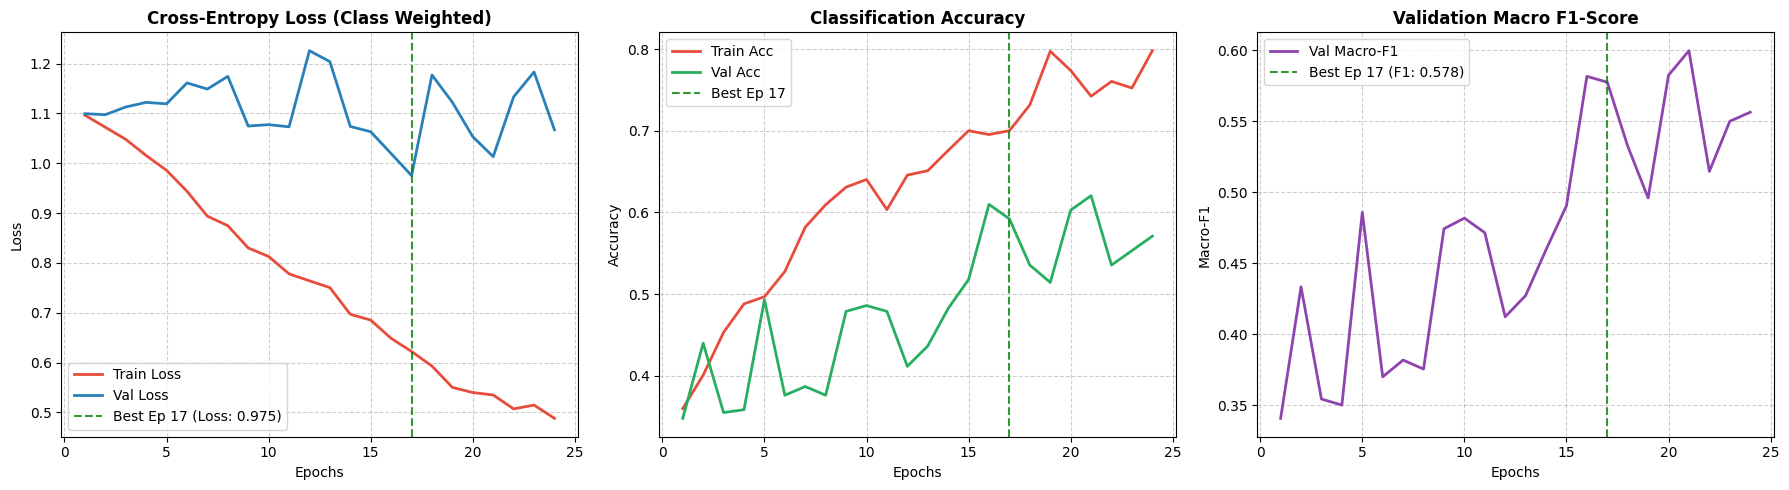

📊 Đã lưu biểu đồ học tập tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/convnextv2_base_training_curves.png


In [11]:
# 11. Trực quan hóa Tiến trình Huấn luyện (Learning Curves)
if len(history["train_loss"]) > 0:
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss curve
    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", color="#e74c3c", lw=2)
    axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", color="#2980b9", lw=2)
    if 'best_epoch' in locals():
        axes[0].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (Loss: {best_val_loss:.3f})")
    axes[0].set_title("Cross-Entropy Loss (Class Weighted)", fontweight="bold")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Accuracy curve
    axes[1].plot(epochs_range, history["train_acc"], label="Train Acc", color="#e74c3c", lw=2)
    axes[1].plot(epochs_range, history["val_acc"], label="Val Acc", color="#27ae60", lw=2)
    if 'best_epoch' in locals():
        axes[1].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch}")
    axes[1].set_title("Classification Accuracy", fontweight="bold")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)

    # Macro-F1 curve
    axes[2].plot(epochs_range, history["val_f1"], label="Val Macro-F1", color="#8e44ad", lw=2)
    if 'best_epoch' in locals():
        axes[2].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (F1: {best_val_f1:.3f})")
    axes[2].set_title("Validation Macro F1-Score", fontweight="bold")
    axes[2].set_xlabel("Epochs")
    axes[2].set_ylabel("Macro-F1")
    axes[2].legend()
    axes[2].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    chart_path = os.path.join(CHECKPOINT_DIR, "convnextv2_base_training_curves.png")
    plt.savefig(chart_path, dpi=200)
    plt.show()
    print(f"📊 Đã lưu biểu đồ học tập tại: {chart_path}")


[*] 🔄 Nạp checkpoint tốt nhất từ: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/best_vision_unimodal.pth...
✅ Đã nạp thành công Checkpoint sạch nhất tại Epoch 17 (Val Loss: 0.9752 | Val F1: 0.5775)


Đánh giá Test Set:   0%|          | 0/19 [00:00<?, ?it/s]


🏆 KẾT QUẢ ĐÁNH GIÁ CẤP ĐỘ ẢNH (IMAGE-LEVEL PERFORMANCE)
  • Test Loss                 : 1.3481
  • Test Accuracy (Image-level): 40.60 %
  • Test Macro-F1 (Image-level): 0.4100

📋 [BÁO CÁO PHÂN LOẠI CHI TIẾT THEO TỪNG LỚP]
              precision    recall  f1-score   support

      Unripe     0.3750    0.5500    0.4459        60
        Ripe     0.4034    0.4211    0.4120       114
    Overripe     0.4396    0.3226    0.3721       124

    accuracy                         0.4060       298
   macro avg     0.4060    0.4312    0.4100       298
weighted avg     0.4127    0.4060    0.4022       298

🍈 KẾT QUẢ ĐÁNH GIÁ CẤP ĐỘ QUẢ (FRUIT-LEVEL PERFORMANCE - 24 QUẢ TEST)
  • Test Accuracy (Fruit-level): 45.83 %
  • Test Macro-F1 (Fruit-level): 0.4351

💾 Đã lưu chi tiết dự đoán từng ảnh ra CSV tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/test_predictions_detailed.csv


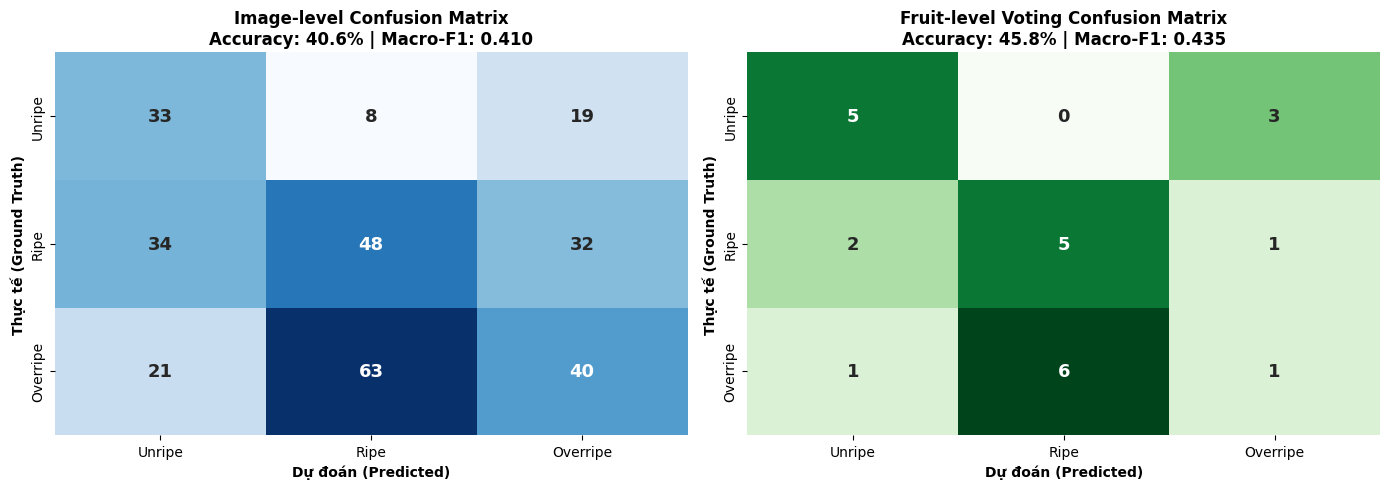

📊 Đã lưu ma trận nhầm lẫn tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/test_confusion_matrices.png

🔎 Phát hiện 177/298 ảnh đoán sai trên tập Test.


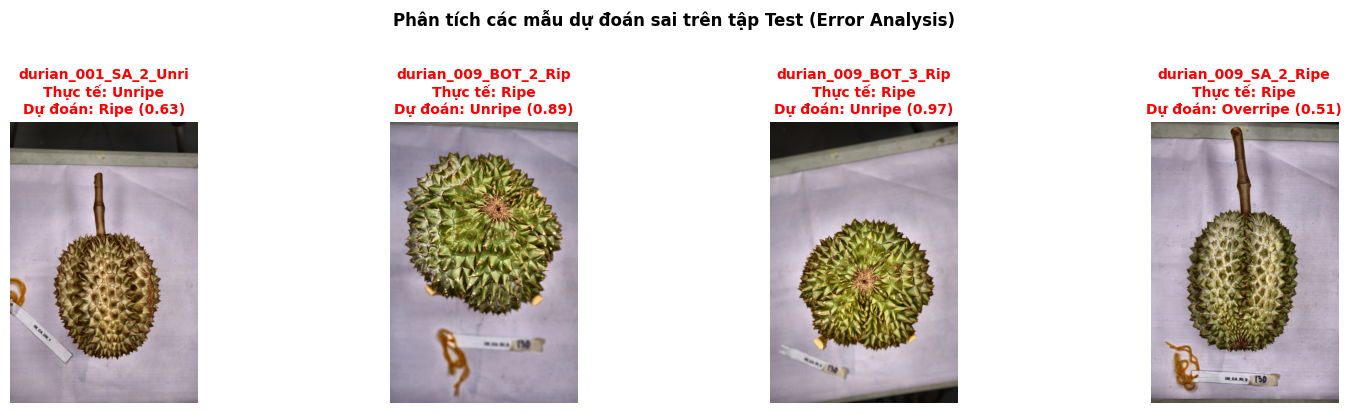

📊 Đã lưu hình ảnh trực quan hóa các ca đoán sai tại: /content/drive/MyDrive/durian-ripeness-cmkd/checkpoints/unimodal/test_misclassified_samples.png


In [12]:
# 12. Đánh giá Độc lập trên tập Test (Cấp độ Ảnh & Cấp độ Quả - Fruit Voting)
if os.path.isfile(BEST_CHECKPOINT_PATH):
    print(f"[*] 🔄 Nạp checkpoint tốt nhất từ: {BEST_CHECKPOINT_PATH}...")
    best_cp = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(best_cp["model_state_dict"])
    print(f"✅ Đã nạp thành công Checkpoint sạch nhất tại Epoch {best_cp.get('epoch', 'N/A')} (Val Loss: {best_cp.get('best_val_loss', 'N/A'):.4f} | Val F1: {best_cp.get('best_val_f1', 0.0):.4f})")
else:
    print("⚠️ Sử dụng trọng số hiện tại của mô hình.")

model.eval()
test_loss = 0.0
all_preds, all_targets, all_probs, all_filenames = [], [], [], []

with torch.no_grad():
    for images, targets, filenames in tqdm(test_loader, desc="Đánh giá Test Set"):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
            logits, _ = model(images)
            loss = criterion(logits, targets)
        
        test_loss += loss.item() * images.size(0)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
        
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        all_probs.extend(probs)
        all_filenames.extend(filenames)

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
test_loss /= len(test_loader.dataset)

# 1. KẾT QUẢ CẤP ĐỘ ẢNH (IMAGE-LEVEL)
img_acc = accuracy_score(all_targets, all_preds)
img_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

print("\n" + "="*65)
print("🏆 KẾT QUẢ ĐÁNH GIÁ CẤP ĐỘ ẢNH (IMAGE-LEVEL PERFORMANCE)")
print("="*65)
print(f"  • Test Loss                 : {test_loss:.4f}")
print(f"  • Test Accuracy (Image-level): {img_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Image-level): {img_macro_f1:.4f}")
print("="*65 + "\n")

print("📋 [BÁO CÁO PHÂN LOẠI CHI TIẾT THEO TỪNG LỚP]")
print(classification_report(all_targets, all_preds, target_names=RIPENESS_ORDER, digits=4))

# 2. KẾT QUẢ CẤP ĐỘ QUẢ (FRUIT-LEVEL VOTING)
test_records = []
for fn, t, p, prob in zip(all_filenames, all_targets, all_preds, all_probs):
    fid = fn.split("_")[0] + "_" + fn.split("_")[1] if len(fn.split("_")) > 1 else fn
    test_records.append({
        "filename": fn,
        "fruit_id": fid,
        "true_label": RIPENESS_ORDER[t],
        "pred_label": RIPENESS_ORDER[p],
        "prob_Unripe": prob[0],
        "prob_Ripe": prob[1],
        "prob_Overripe": prob[2],
        "is_correct": bool(t == p)
    })
df_test_results = pd.DataFrame(test_records)

fruit_voting = df_test_results.groupby("fruit_id").agg({
    "true_label": "first",
    "prob_Unripe": "mean",
    "prob_Ripe": "mean",
    "prob_Overripe": "mean"
}).reset_index()

fruit_probs = fruit_voting[["prob_Unripe", "prob_Ripe", "prob_Overripe"]].values
fruit_voting["voted_label"] = [RIPENESS_ORDER[i] for i in np.argmax(fruit_probs, axis=1)]
fruit_y_true = fruit_voting["true_label"].map(LABEL_TO_IDX)
fruit_y_pred = fruit_voting["voted_label"].map(LABEL_TO_IDX)

fruit_acc = accuracy_score(fruit_y_true, fruit_y_pred)
fruit_macro_f1 = f1_score(fruit_y_true, fruit_y_pred, average="macro", zero_division=0)

print("="*65)
print(f"🍈 KẾT QUẢ ĐÁNH GIÁ CẤP ĐỘ QUẢ (FRUIT-LEVEL PERFORMANCE - {len(fruit_voting)} QUẢ TEST)")
print("="*65)
print(f"  • Test Accuracy (Fruit-level): {fruit_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Fruit-level): {fruit_macro_f1:.4f}")
print("="*65 + "\n")

csv_test_path = os.path.join(CHECKPOINT_DIR, "test_predictions_detailed.csv")
df_test_results.to_csv(csv_test_path, index=False, encoding="utf-8")
print(f"💾 Đã lưu chi tiết dự đoán từng ảnh ra CSV tại: {csv_test_path}")

# 3. VẼ MA TRẬN NHẦM LẪN ĐÔI
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_img = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_img, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f"Image-level Confusion Matrix\nAccuracy: {img_acc*100:.1f}% | Macro-F1: {img_macro_f1:.3f}", fontweight="bold")
axes[0].set_xlabel("Dự đoán (Predicted)", fontweight="bold")
axes[0].set_ylabel("Thực tế (Ground Truth)", fontweight="bold")

cm_fruit = confusion_matrix(fruit_y_true, fruit_y_pred)
sns.heatmap(cm_fruit, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[1].set_title(f"Fruit-level Voting Confusion Matrix\nAccuracy: {fruit_acc*100:.1f}% | Macro-F1: {fruit_macro_f1:.3f}", fontweight="bold")
axes[1].set_xlabel("Dự đoán (Predicted)", fontweight="bold")
axes[1].set_ylabel("Thực tế (Ground Truth)", fontweight="bold")

plt.tight_layout()
cm_fig_path = os.path.join(CHECKPOINT_DIR, "test_confusion_matrices.png")
plt.savefig(cm_fig_path, dpi=200)
plt.show()
print(f"📊 Đã lưu ma trận nhầm lẫn tại: {cm_fig_path}")

# 4. TRỰC QUAN HÓA CÁC CA ĐOÁN SAI
misclassified = df_test_results[~df_test_results["is_correct"]]
print(f"\n🔎 Phát hiện {len(misclassified)}/{len(df_test_results)} ảnh đoán sai trên tập Test.")
if len(misclassified) > 0:
    sample_errors = misclassified.head(min(4, len(misclassified)))
    fig, axes = plt.subplots(1, len(sample_errors), figsize=(4 * len(sample_errors), 4))
    if len(sample_errors) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample_errors.iterrows()):
        img_path = None
        for sp_item in image_splits["test"]:
            if sp_item["filename"] == row["filename"]:
                img_path = sp_item["filepath"]
                break
        if img_path and os.path.isfile(img_path):
            disp_img = cv2.imread(img_path)
            disp_img = cv2.cvtColor(disp_img, cv2.COLOR_BGR2RGB)
            ax.imshow(disp_img)
        ax.set_title(f"{row['filename'][:20]}\nThực tế: {row['true_label']}\nDự đoán: {row['pred_label']} ({row[f'prob_{row["pred_label"]}']:.2f})",
                     color="red", fontsize=10, fontweight="bold")
        ax.axis("off")
    plt.suptitle("Phân tích các mẫu dự đoán sai trên tập Test (Error Analysis)", fontweight="bold", y=1.02)
    plt.tight_layout()
    err_path = os.path.join(CHECKPOINT_DIR, "test_misclassified_samples.png")
    plt.savefig(err_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"📊 Đã lưu hình ảnh trực quan hóa các ca đoán sai tại: {err_path}")


## 🎯 Tổng kết & Bước tiếp theo

1. **Kết quả đạt được:**
   - Trọng số tối ưu đã được lưu tại **`best_vision_unimodal.pth`**.
   - Vector trích xuất đặc trưng thị giác 1024 chiều đã được lưu riêng tại **`vision_backbone_teacher.pth`**.
   - Toàn bộ bảng số liệu phân tích dự đoán chi tiết đã được xuất ra **`test_predictions_detailed.csv`**.
2. **Giai đoạn tiếp theo (Multi-Modal Teacher Fusion):**
   - Nạp `vision_backbone_teacher.pth` vào nhánh Vision của mô hình Teacher Đa phương thức.
   - Kết hợp cùng vector âm thanh ($f_{audio}$) của Member 2 và cảm biến ($f_{sensor}$) của Member 3 để hoàn thành bộ Teacher mạnh nhất trước khi chưng cất sang Student.
